In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("death_clean.csv")
df

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
545,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
546,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
547,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
548,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


In [28]:
x = df[["Cause", "Type"]]
y = df[["Total Deaths"]]

x_encode = pd.get_dummies(x, columns=["Cause", "Type"])
scaler = StandardScaler()
y_norm = scaler.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_encode, y_norm, test_size=0.3, random_state=0)

print(x_train)
print(y_train)

     Cause_AIDS  Cause_Abrasi Air Laut  Cause_Aksi Teror dan Sabotase  \
224       False                  False                          False   
208       False                  False                          False   
38        False                  False                          False   
390       False                  False                          False   
364       False                  False                          False   
..          ...                    ...                            ...   
70        False                  False                          False   
277       False                  False                          False   
9          True                  False                          False   
359       False                  False                          False   
192       False                  False                          False   

     Cause_Angin Puting Beliung  Cause_Angin Siklon Tropis  Cause_Angin Topan  \
224                       False           

In [29]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
y_pred

array([-5.07812500e-02, -4.51397813e+12,  1.19140625e-01, -4.00390625e-01,
       -3.49609375e-01, -4.62890625e-01, -6.58203125e-01,  1.19140625e-01,
       -8.00781250e-02, -5.82031250e-01, -5.29296875e-01, -4.16015625e-01,
       -4.94140625e-01,  4.42408495e+13, -5.66406250e-01, -3.11961953e+13,
        2.40039062e+00, -4.16015625e-01,  1.25413249e+13,  1.77734375e-01,
       -8.00781250e-02, -8.00781250e-02, -4.16015625e-01,  6.58203125e-01,
       -5.66406250e-01,  1.25413249e+13, -8.00781250e-02,  3.72070312e+00,
        1.26757812e+00, -1.12035411e+12, -4.57031250e-01, -2.28515625e-01,
       -4.00390625e-01, -4.57031250e-01, -3.32031250e-02,  8.24218750e-01,
       -1.73828125e-01, -5.42968750e-01, -5.50781250e-01, -4.70703125e-01,
        9.76562500e-02, -5.42968750e-01, -5.50781250e-01, -5.42968750e-01,
       -5.44921875e-01, -4.57031250e-01, -2.98828125e-01, -4.62890625e-01,
       -8.40280460e+12, -4.57031250e-01,  4.19775390e+13, -5.13671875e-01,
        1.77734375e-01,  

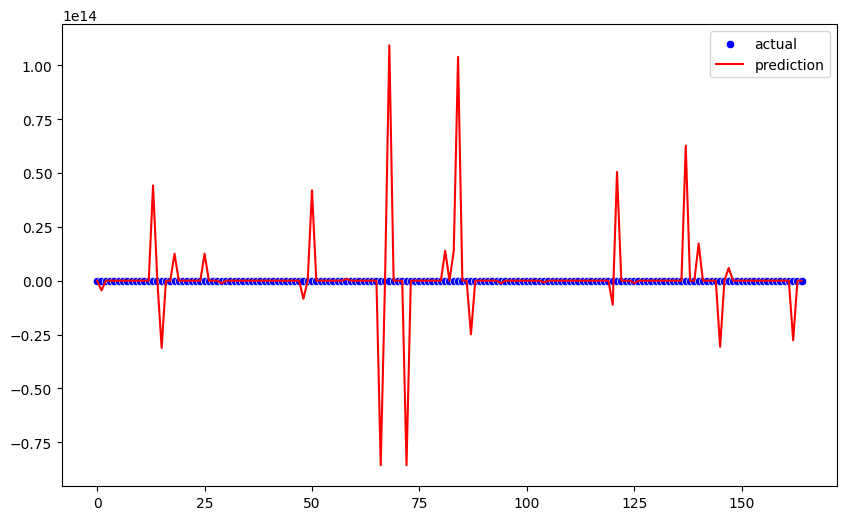

In [30]:
plt.figure(figsize=(10,6))
sns.scatterplot(x = range(len(y_test)), y = y_test, color = "blue", label = "actual")
sns.lineplot(x = range(len(y_pred)), y = y_pred, color = "red", label = "prediction")
plt.legend()
plt.show()

cause = aids, pilek, batuk, sakit perut, pusing
type = alam, alam, alam, alam, alam
death = 20, 30, 40, 50, 60

kondisi (train = 80%, test = 20% / 0.2 )

x_train :
cause = aids, pilek, batuk
type = alam, alam, alam

x_test : 
cause = sakit perut, pusing
type = alam, alam

y_train : 
death = 20, 30, 40

y_test : 
death = 50, 60

fit = x_train, y_train

y_pred = predict(x_test) = cause (sakit perut), type(alam), death = ?